<a href="https://colab.research.google.com/github/jomana2006/IoT-Principles-Project/blob/main/IoTProjectJomana.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Imports and Data Loading

In [80]:
# imports

import kagglehub
from kagglehub import KaggleDatasetAdapter
from statsmodels.tsa.seasonal import seasonal_decompose
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
SmartData = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "taranvee/smart-home-dataset-with-weather-information",
    "HomeC.csv"
)

Using Colab cache for faster access to the 'smart-home-dataset-with-weather-information' dataset.


/usr/local/lib/python3.13/dist-packages/kagglehub/pandas_datasets.py:92: DtypeWarning: Columns (0,27) have mixed types. Specify dtype option on import or set low_memory=False.
  result = read_function(


**Feature Details from Kaggle: https://www.kaggle.com/datasets/taranvee/smart-home-dataset-with-weather-information/data**

- `time`
- `use [kW]` = Total energy consumption
- `gen [kW]` = Total energy generated by solar/other power resources.
- `House overall [kW]` = Overall house energy consumption
- `Dishwasher [kW]` = Energy consumed by dishwasher
- `Furnace 1 [kW]` = Energy consumed by furnace 1
- `Furnace 2 [kW]` = Energy consumed by furnace 2
- `Home office [kW]` = Energy consumed by home office
- `Fridge [kW]` = Energy consumed by fridge
- `Wine Cellar [kW]` = Energy consumed by wine cellar
- `Garage door [kW]` = Energy consumed by garage door
- `Kitchen 12 [kW]` = Energy consumed by kitchen 1
- `Kitchen 14 [kW]` = Energy consumed by kitchen 2
- `Kitchen 38 [kW]` = Energy consumed by kitchen 3
- `Barn [kW]` = Energy consumed by barn
- `Well [kW]` = Energy consumed by well
- `Microwave [kW]` = Energy consumed by microwave
- `Living room [kW]` = Energy consumed by living room
- `Solar [kW]` = Solar power generated
- `temperature`
- `icon` = Weather Condition
- `humidity`
- `visibility`
- `summary` = Overall Weather
- `apparantTemperature` = Temperature a person assumes, e.g. 'It feels like its 30C'
- `pressure`
- `windSpeed`
- `cloudCover`
- `windBearing`
- `precipIntensity` = Precipitation Intensity
- `dewPoint`
- `precipProbability` = Precipitation Probability

The column names will be changed for consistency and understandability.

**`use [kW]` and `House overall [kW]` are 100% identical. One will be *dropped* while the other will remain.**

**`gen [kW]` and `Solar  [kW]` are 100% identical. But the feature description on kaggle states that `gen [kW]` is *solar power generated and any other power generation resources*. So, we will either drop `Solar [kW]` and keep `gen [kW]` as an all-power-source identifier, or we will keep them both.**

---

### Data Exploration

In [4]:
SmartData.head(10)

,time,use [kW],gen [kW],House overall [kW],Dishwasher [kW],Furnace 1 [kW],Furnace 2 [kW],Home office [kW],Fridge [kW],Wine cellar [kW],...,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability
0,1451624400,0.932833,0.003483,0.932833,0.000033,0.020700,0.061917,0.442633,0.124150,0.006983,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
1,1451624401,0.934333,0.003467,0.934333,0.000000,0.020717,0.063817,0.444067,0.124000,0.006983,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2,1451624402,0.931817,0.003467,0.931817,0.000017,0.020700,0.062317,0.446067,0.123533,0.006983,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
3,1451624403,1.022050,0.003483,1.022050,0.000017,0.106900,0.068517,0.446583,0.123133,0.006983,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
4,1451624404,1.139400,0.003467,1.139400,0.000133,0.236933,0.063983,0.446533,0.122850,0.006850,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
5,1451624405,1.391867,0.003433,1.391867,0.000283,0.503250,0.063667,0.447033,0.122300,0.006717,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
6,1451624406,1.366217,0.003450,1.366217,0.000283,0.499400,0.063717,0.443267,0.122050,0.006733,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
7,1451624407,1.431900,0.003417,1.431900,0.000250,0.477867,0.178633,0.444283,0.121800,0.006783,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
8,1451624408,1.627300,0.003417,1.627300,0.000183,0.447650,0.365700,0.441467,0.121617,0.006950,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
9,1451624409,1.735383,0.003417,1.735383,0.000017,0.171550,0.682500,0.438733,0.121633,0.007233,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0


In [5]:
SmartData.shape

(503911, 32)

In [6]:
SmartData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503911 entries, 0 to 503910
Data columns (total 32 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   time                 503911 non-null  object 
 1   use [kW]             503910 non-null  float64
 2   gen [kW]             503910 non-null  float64
 3   House overall [kW]   503910 non-null  float64
 4   Dishwasher [kW]      503910 non-null  float64
 5   Furnace 1 [kW]       503910 non-null  float64
 6   Furnace 2 [kW]       503910 non-null  float64
 7   Home office [kW]     503910 non-null  float64
 8   Fridge [kW]          503910 non-null  float64
 9   Wine cellar [kW]     503910 non-null  float64
 10  Garage door [kW]     503910 non-null  float64
 11  Kitchen 12 [kW]      503910 non-null  float64
 12  Kitchen 14 [kW]      503910 non-null  float64
 13  Kitchen 38 [kW]      503910 non-null  float64
 14  Barn [kW]            503910 non-null  float64
 15  Well [kW]        

In [7]:
SmartData.describe().T

,count,mean,std,min,25%,50%,75%,max
use [kW],503910.0,0.858962,1.058207,0.000000,0.367667,0.562333,0.970250,14.714567
gen [kW],503910.0,0.076229,0.128428,0.000000,0.003367,0.004283,0.083917,0.613883
House overall [kW],503910.0,0.858962,1.058207,0.000000,0.367667,0.562333,0.970250,14.714567
Dishwasher [kW],503910.0,0.031368,0.190951,0.000000,0.000000,0.000017,0.000233,1.401767
Furnace 1 [kW],503910.0,0.099210,0.169059,0.000017,0.020233,0.020617,0.068733,1.934083
Furnace 2 [kW],503910.0,0.136779,0.178631,0.000067,0.064400,0.066633,0.080633,0.794933
Home office [kW],503910.0,0.081287,0.104466,0.000083,0.040383,0.042217,0.068283,0.971750
Fridge [kW],503910.0,0.063556,0.076199,0.000067,0.005083,0.005433,0.125417,0.851267
Wine cellar [kW],503910.0,0.042137,0.057967,0.000017,0.007133,0.008083,0.053192,1.273933
Garage door [kW],503910.0,0.014139,0.014292,0.000017,0.012733,0.012933,0.013100,1.088983


In [23]:
# Renaming Columns for consistency

ColumnNames = [
    "Time", "EnergyConsumption [kW]", "EnergyGenerated [kW]",
    "OverallHouse [kW]", "Dishwasher [kW]", "Furnace1 [kW]",
    "Furnace2 [kW]", "HomeOffice [kW]", "Fridge [kW]", "WineCellar [kW]",
    "GarageDoor [kW]", "Kitchen1 [kW]", "Kitchen2 [kW]", "Kitchen3 [kW]",
    "Barn [kW]", "Well [kW]", "Microwave [kW]", "LivingRoom [kW]",
    "SolarPower [kW]", "Temperature", "WeatherCondition", "Humidity",
    "Visibility", "OverallWeather", "ApparantTemperature", "Pressure",
    "WindSpeed", "CloudCoverage", "WindBearing", "PrecipitationIntensity",
    "DewPoint", "PrecipitationProbabiliy"
]

SmartData.columns = ColumnNames

In [24]:
SmartData.columns

Index(['Time', 'EnergyConsumption [kW]', 'EnergyGenerated [kW]',
       'OverallHouse [kW]', 'Dishwasher [kW]', 'Furnace1 [kW]',
       'Furnace2 [kW]', 'HomeOffice [kW]', 'Fridge [kW]', 'WineCellar [kW]',
       'GarageDoor [kW]', 'Kitchen1 [kW]', 'Kitchen2 [kW]', 'Kitchen3 [kW]',
       'Barn [kW]', 'Well [kW]', 'Microwave [kW]', 'LivingRoom [kW]',
       'SolarPower [kW]', 'Temperature', 'WeatherCondition', 'Humidity',
       'Visibility', 'OverallWeather', 'ApparantTemperature', 'Pressure',
       'WindSpeed', 'CloudCoverage', 'WindBearing', 'PrecipitationIntensity',
       'DewPoint', 'PrecipitationProbabiliy'],
      dtype='object')

In [73]:
# Fixing the time UNIX Column as it is supposed to be in minutes and not UNIX seconds.

Start = pd.to_datetime(SmartData["Time"].iloc[0], unit='s')
SmartData["Time"] = pd.date_range(start=Start, periods=len(SmartData), freq="min")
SmartData.set_index("Time", inplace=True)
SmartData.head(10)

,EnergyConsumption [kW],EnergyGenerated [kW],OverallHouse [kW],Dishwasher [kW],Furnace1 [kW],Furnace2 [kW],HomeOffice [kW],Fridge [kW],WineCellar [kW],GarageDoor [kW],...,Visibility,OverallWeather,ApparantTemperature,Pressure,WindSpeed,CloudCoverage,WindBearing,PrecipitationIntensity,DewPoint,PrecipitationProbabiliy
Time,,,,,,,,,,,,,,,,,,,,,
2016-01-01 05:00:00,0.932833,0.003483,0.932833,0.000033,0.020700,0.061917,0.442633,0.124150,0.006983,0.013083,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2016-01-01 05:01:00,0.934333,0.003467,0.934333,0.000000,0.020717,0.063817,0.444067,0.124000,0.006983,0.013117,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2016-01-01 05:02:00,0.931817,0.003467,0.931817,0.000017,0.020700,0.062317,0.446067,0.123533,0.006983,0.013083,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2016-01-01 05:03:00,1.022050,0.003483,1.022050,0.000017,0.106900,0.068517,0.446583,0.123133,0.006983,0.013000,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2016-01-01 05:04:00,1.139400,0.003467,1.139400,0.000133,0.236933,0.063983,0.446533,0.122850,0.006850,0.012783,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2016-01-01 05:05:00,1.391867,0.003433,1.391867,0.000283,0.503250,0.063667,0.447033,0.122300,0.006717,0.012433,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2016-01-01 05:06:00,1.366217,0.003450,1.366217,0.000283,0.499400,0.063717,0.443267,0.122050,0.006733,0.012417,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2016-01-01 05:07:00,1.431900,0.003417,1.431900,0.000250,0.477867,0.178633,0.444283,0.121800,0.006783,0.012550,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0
2016-01-01 05:08:00,1.627300,0.003417,1.627300,0.000183,0.447650,0.365700,0.441467,0.121617,0.006950,0.012717,...,10.0,Clear,29.26,1016.91,9.18,cloudCover,282.0,0.0,24.4,0.0


In [74]:
print(f"Date Range: {SmartData.index.min()} to {SmartData.index.max()}")

Date Range: 2016-01-01 05:00:00 to 2016-12-16 03:30:00


There are about 503,910 readings (from the `.shape()` cell), each is read in one minute, from January 2016 to Mid-December 2016, totalling to around 350 days.

In [79]:
# Resampling minute points into hourly and daily points
# so that its not a lot of data on the SARIMA Model

yHourly = SmartData["EnergyConsumption [kW]"].resample('h').mean()
yDaily = SmartData["EnergyConsumption [kW]"].resample('d').mean()

print("Minute Points: ", len(SmartData))
print("Hourly Points: ", len(yHourly))
print("Daily Points: ", len(yDaily))

Minute Points:  503911
Hourly Points:  8399
Daily Points:  351


---

### Data Visualisation

*Singular Variable Visualisation*

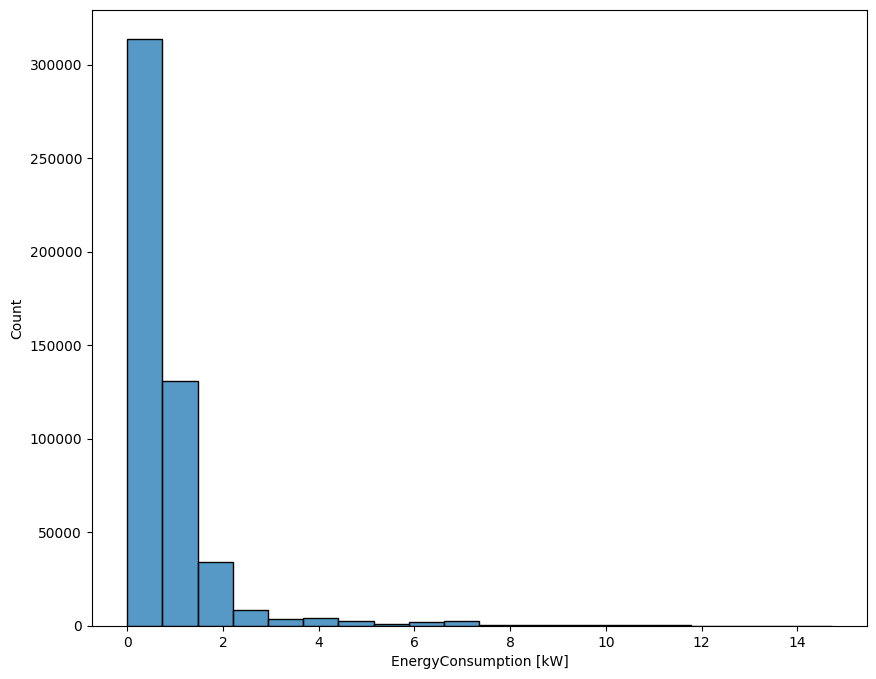

In [34]:
plt.figure(figsize=(10, 8))
sns.histplot(data=SmartData, x="EnergyConsumption [kW]", bins=20)
plt.show()

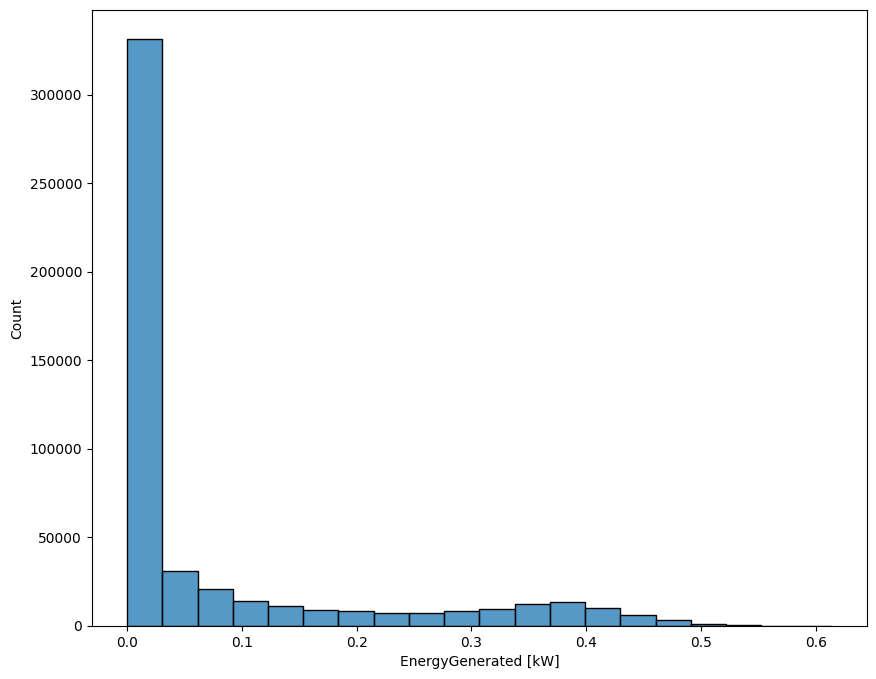

In [36]:
plt.figure(figsize=(10, 8))
sns.histplot(data=SmartData, x="EnergyGenerated [kW]", bins=20)
plt.show()

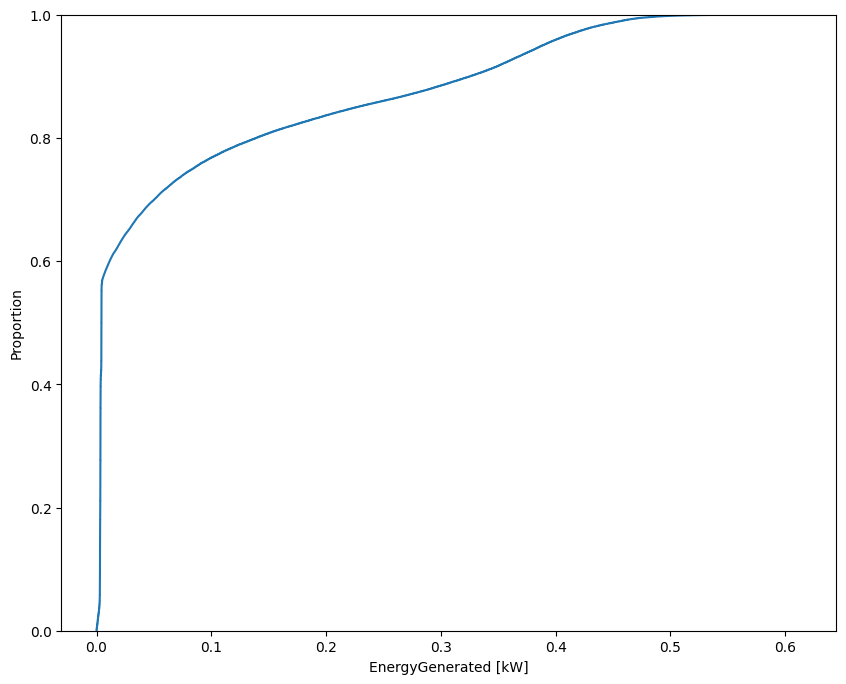

In [37]:
plt.figure(figsize=(10, 8))
sns.ecdfplot(data=SmartData, x="EnergyGenerated [kW]")
plt.show()

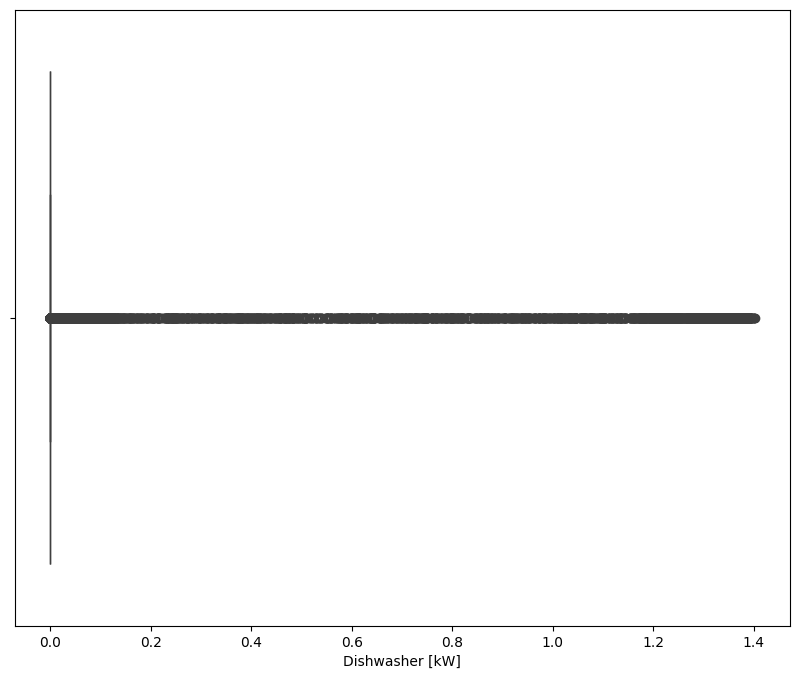

In [38]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Dishwasher [kW]")
plt.show()

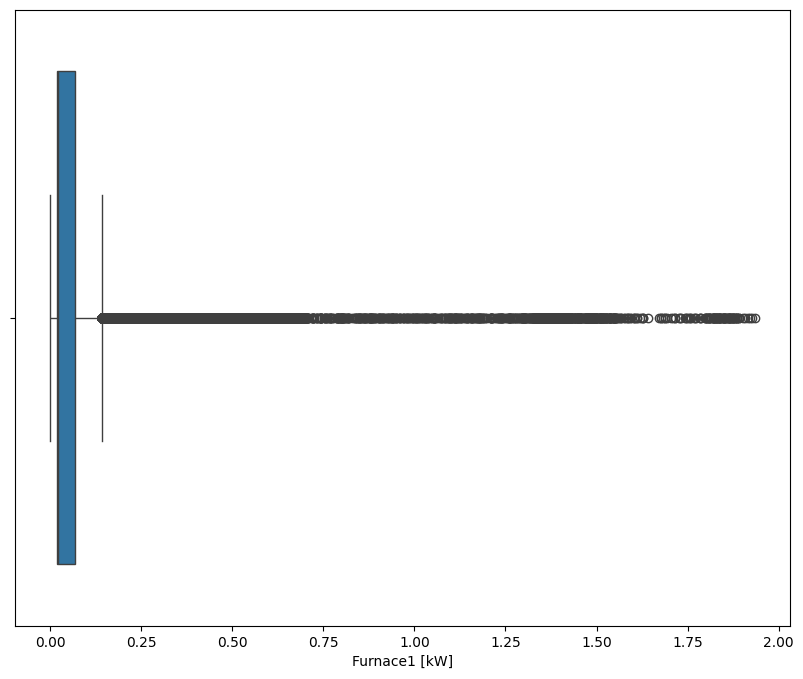

In [39]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Furnace1 [kW]")
plt.show()

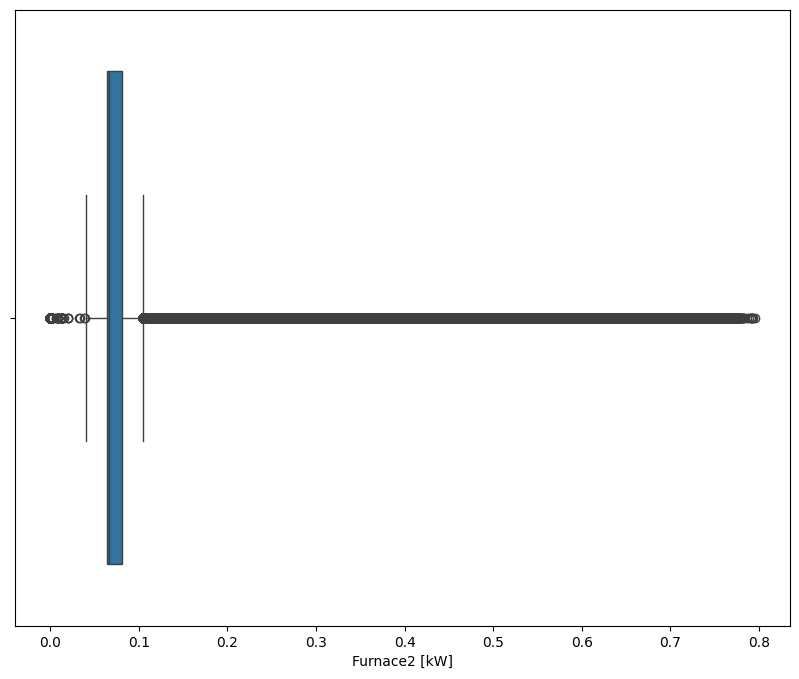

In [40]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Furnace2 [kW]")
plt.show()

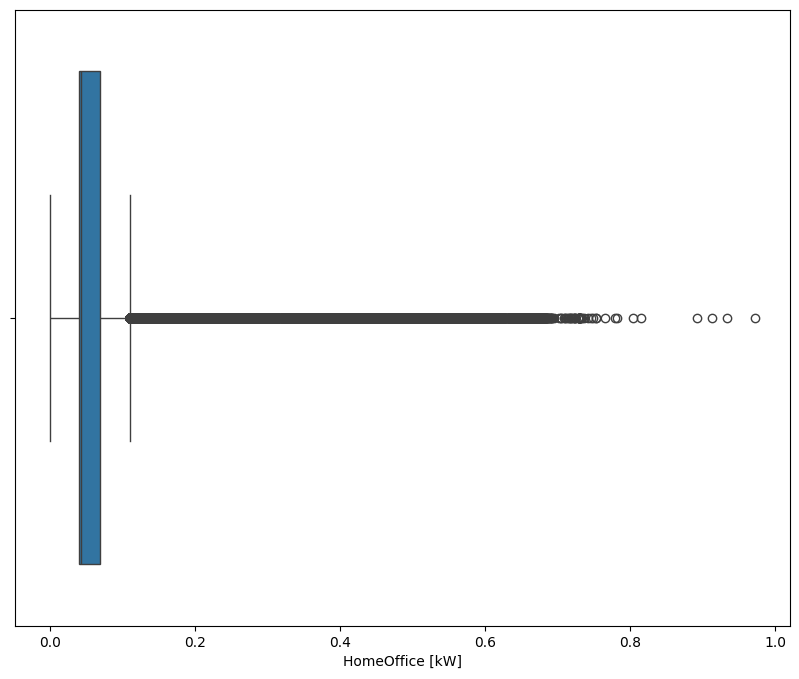

In [41]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="HomeOffice [kW]")
plt.show()

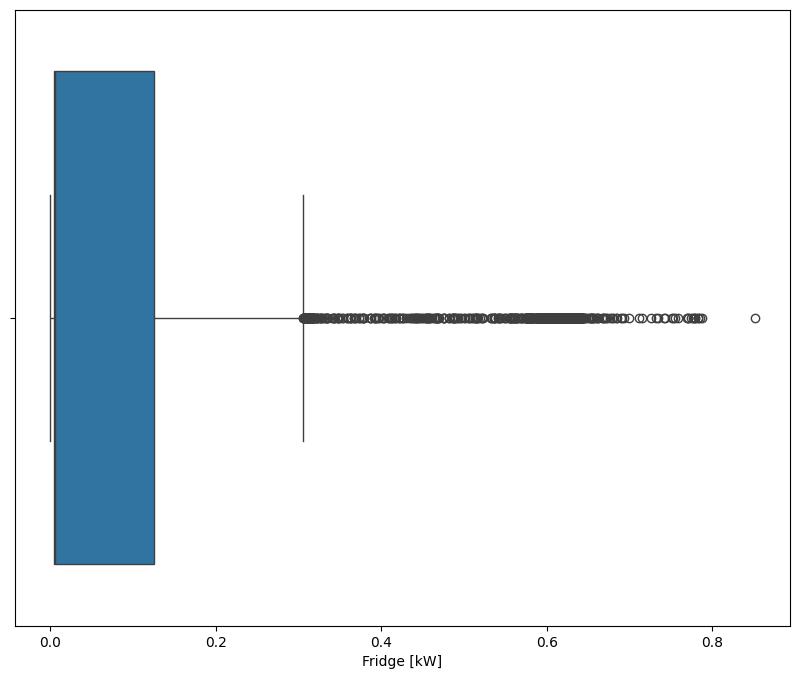

In [42]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Fridge [kW]")
plt.show()

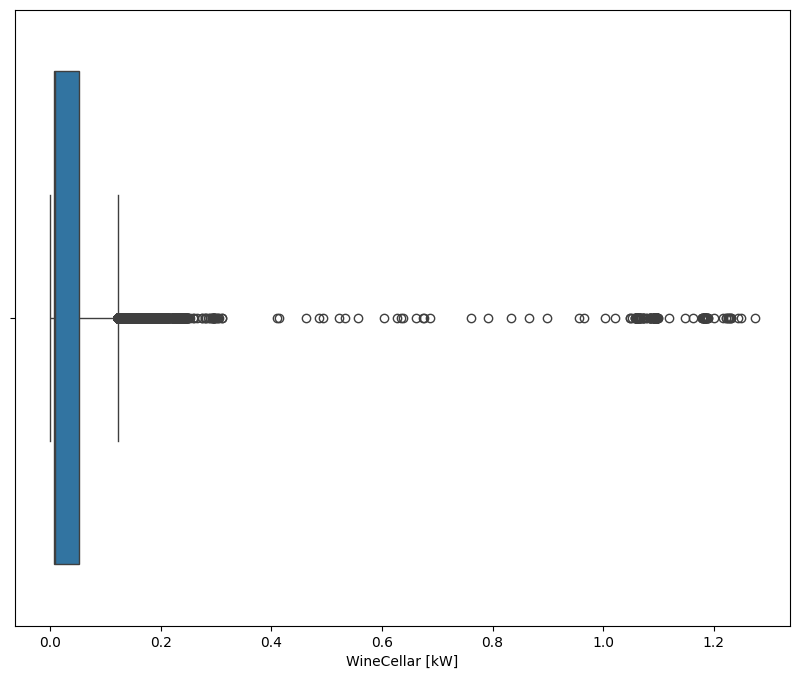

In [43]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="WineCellar [kW]")
plt.show()

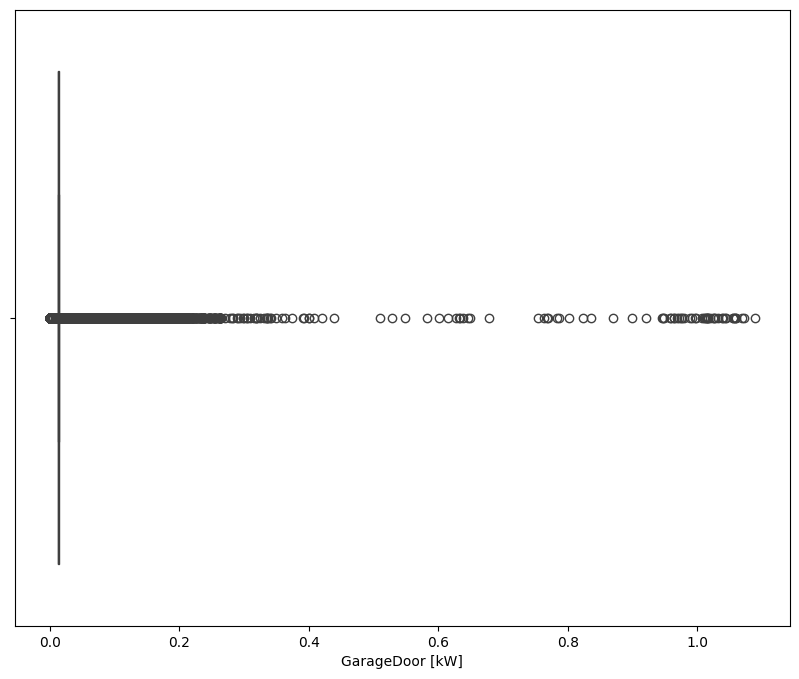

In [44]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="GarageDoor [kW]")
plt.show()

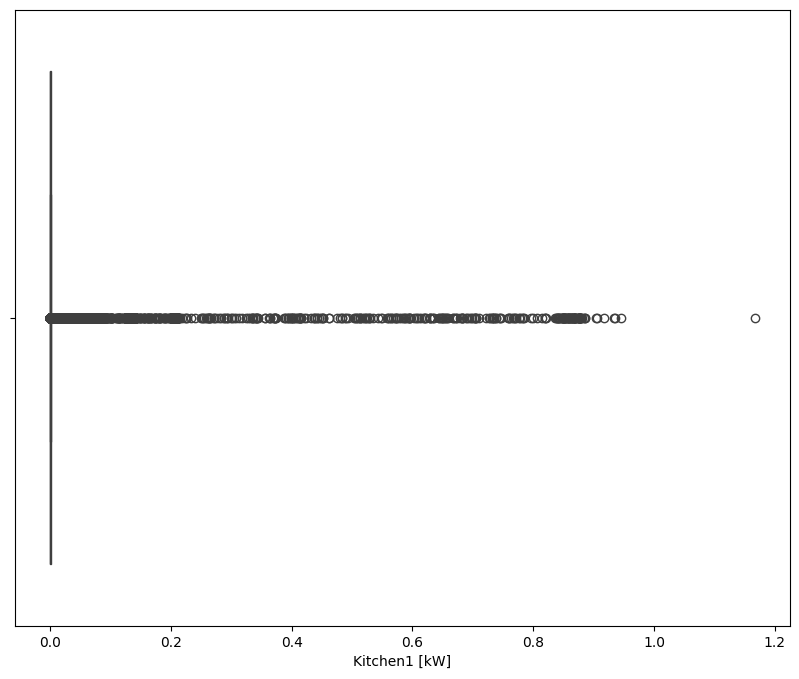

In [45]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Kitchen1 [kW]")
plt.show()

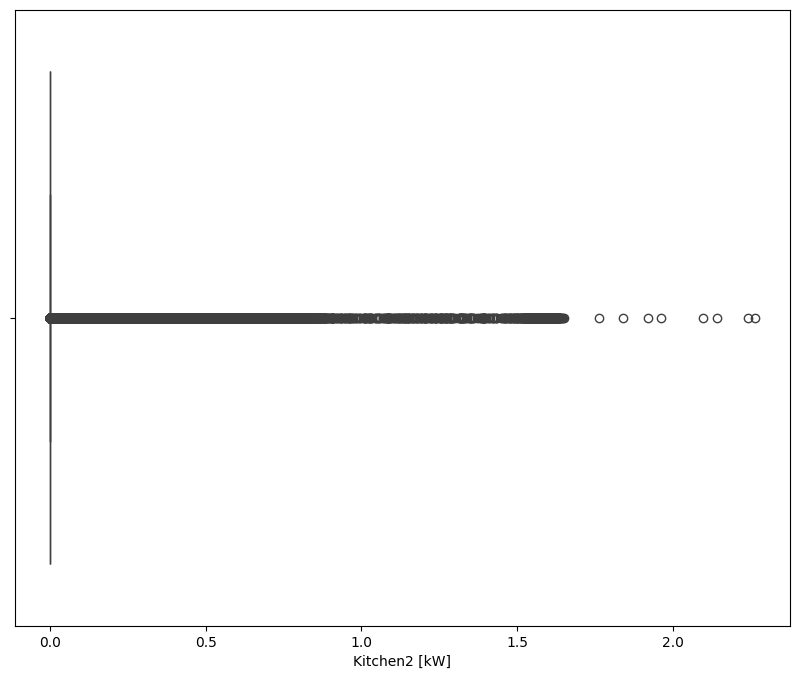

In [46]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Kitchen2 [kW]")
plt.show()

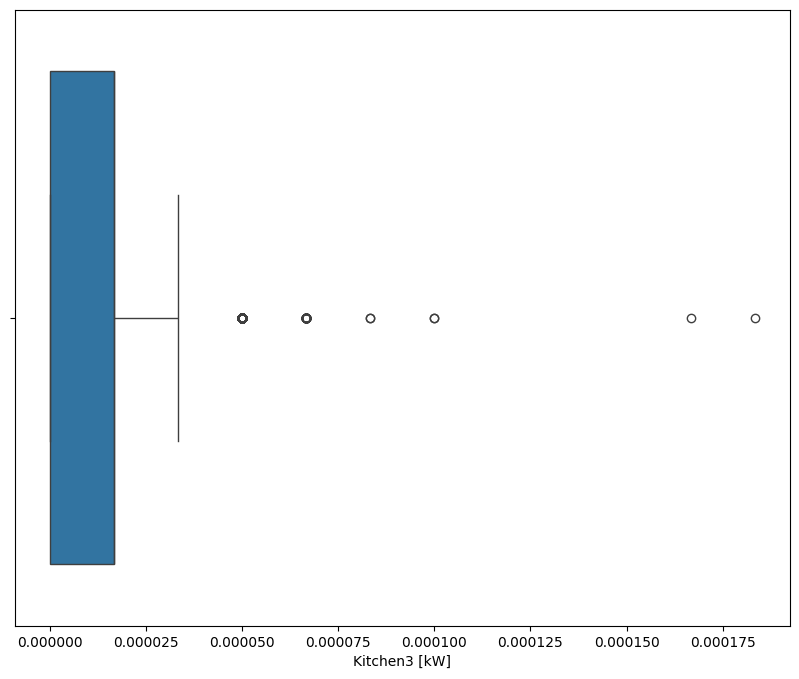

In [47]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Kitchen3 [kW]")
plt.show()

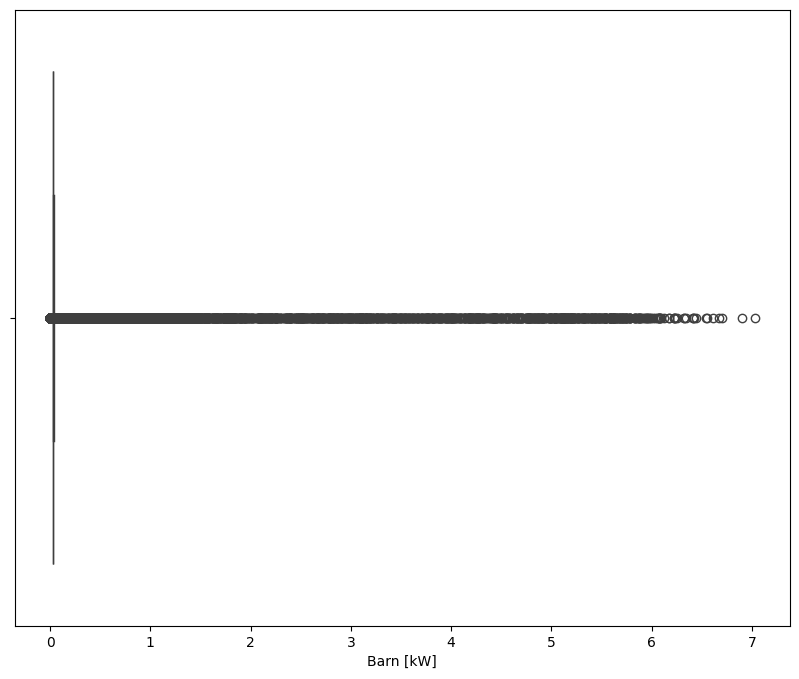

In [48]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Barn [kW]")
plt.show()

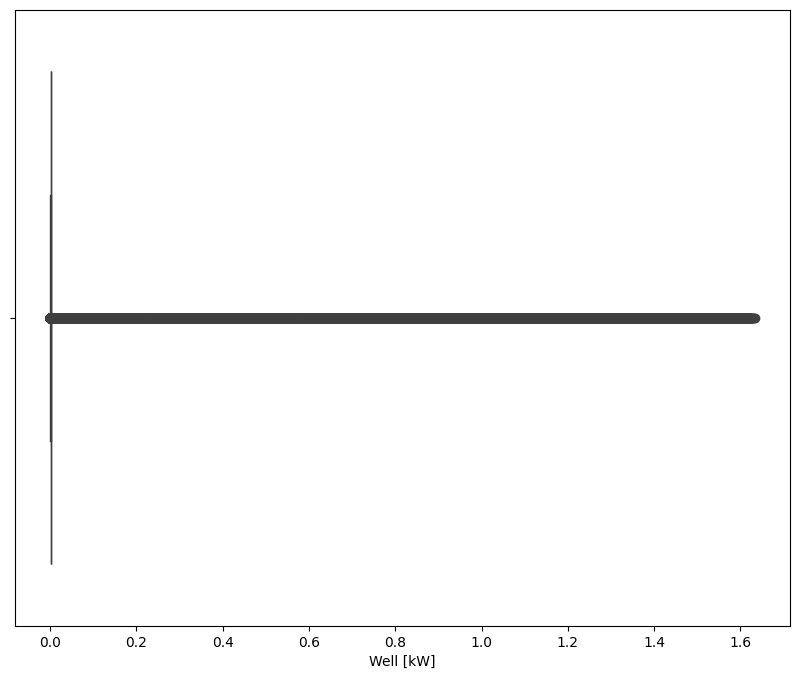

In [49]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Well [kW]")
plt.show()

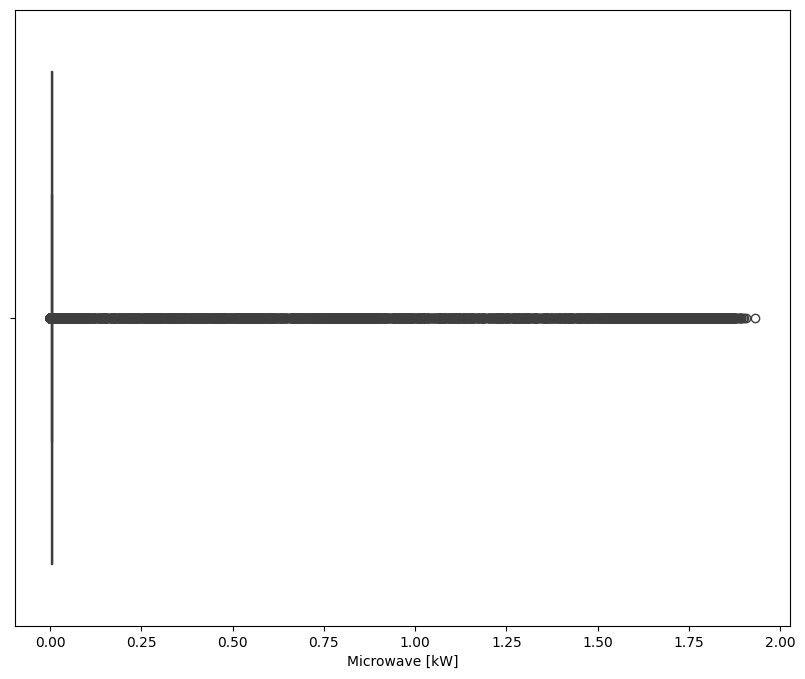

In [50]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="Microwave [kW]")
plt.show()

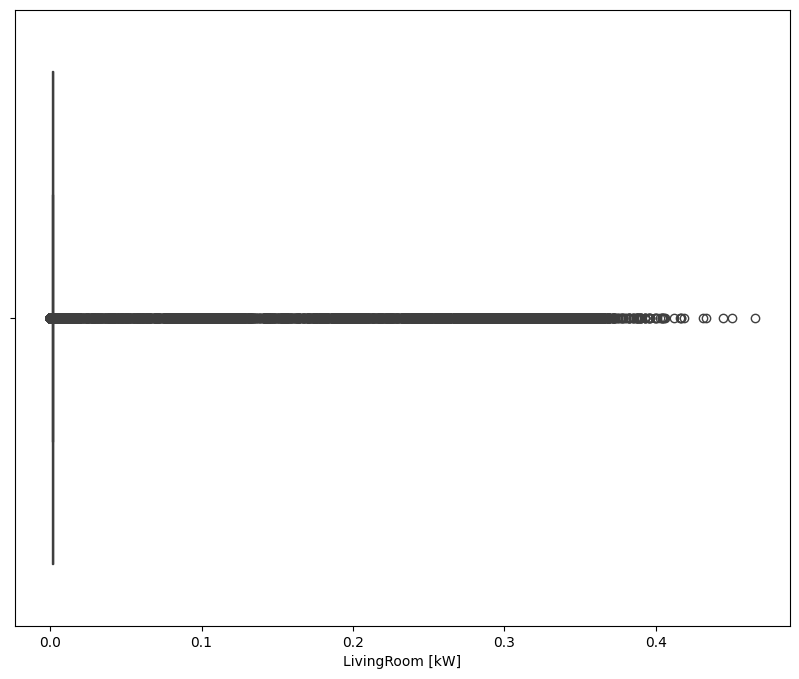

In [51]:
plt.figure(figsize=(10, 8))
sns.boxplot(data=SmartData, x="LivingRoom [kW]")
plt.show()

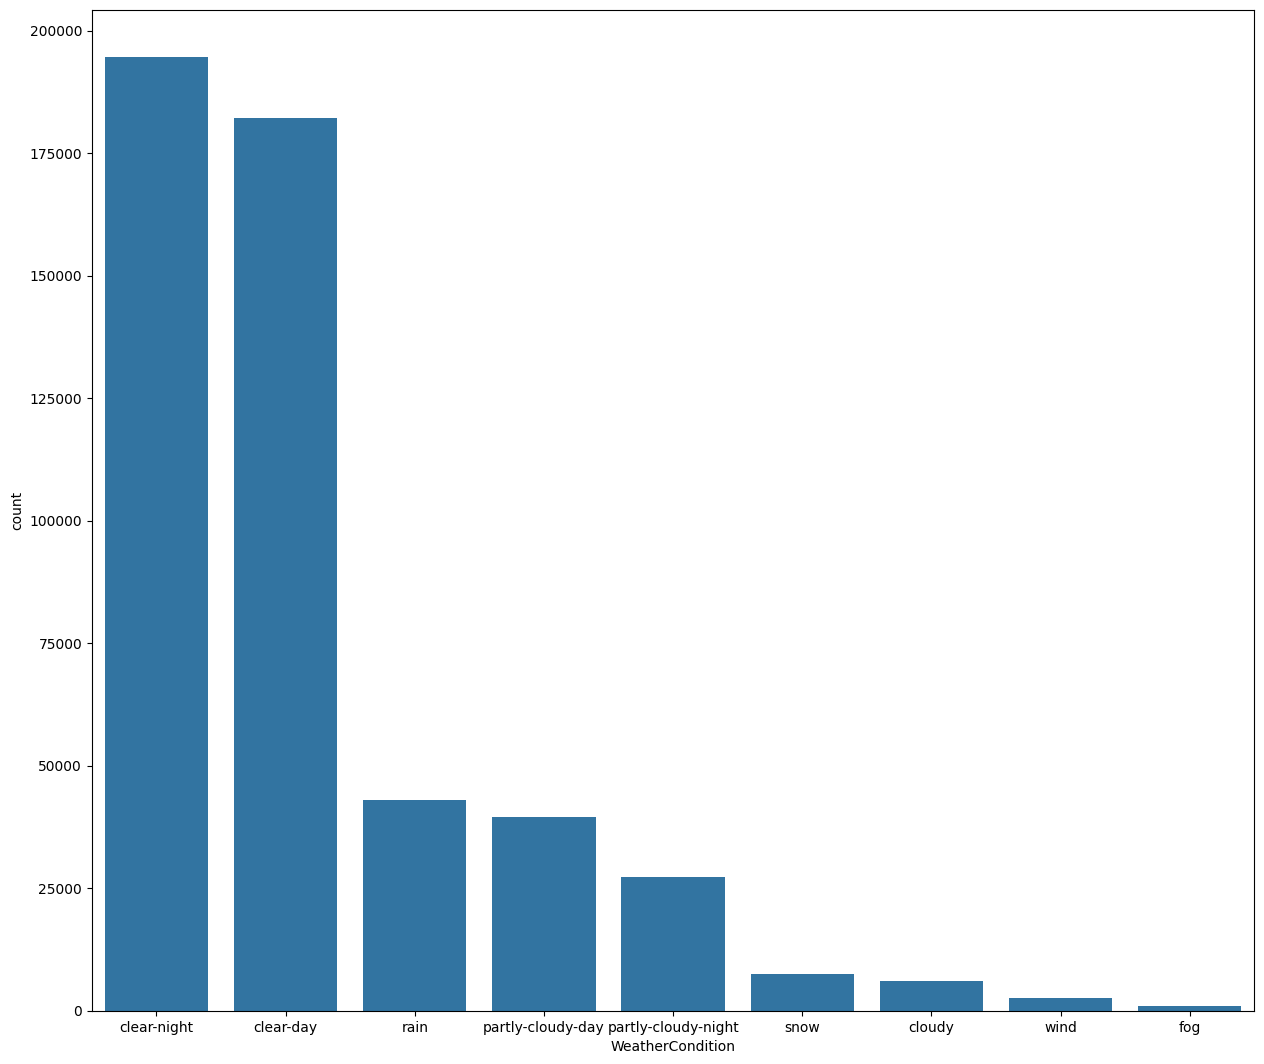

In [57]:
plt.figure(figsize=(15, 13))
order = SmartData["WeatherCondition"].value_counts().index
sns.countplot(data=SmartData, x="WeatherCondition", order=order)
plt.show()

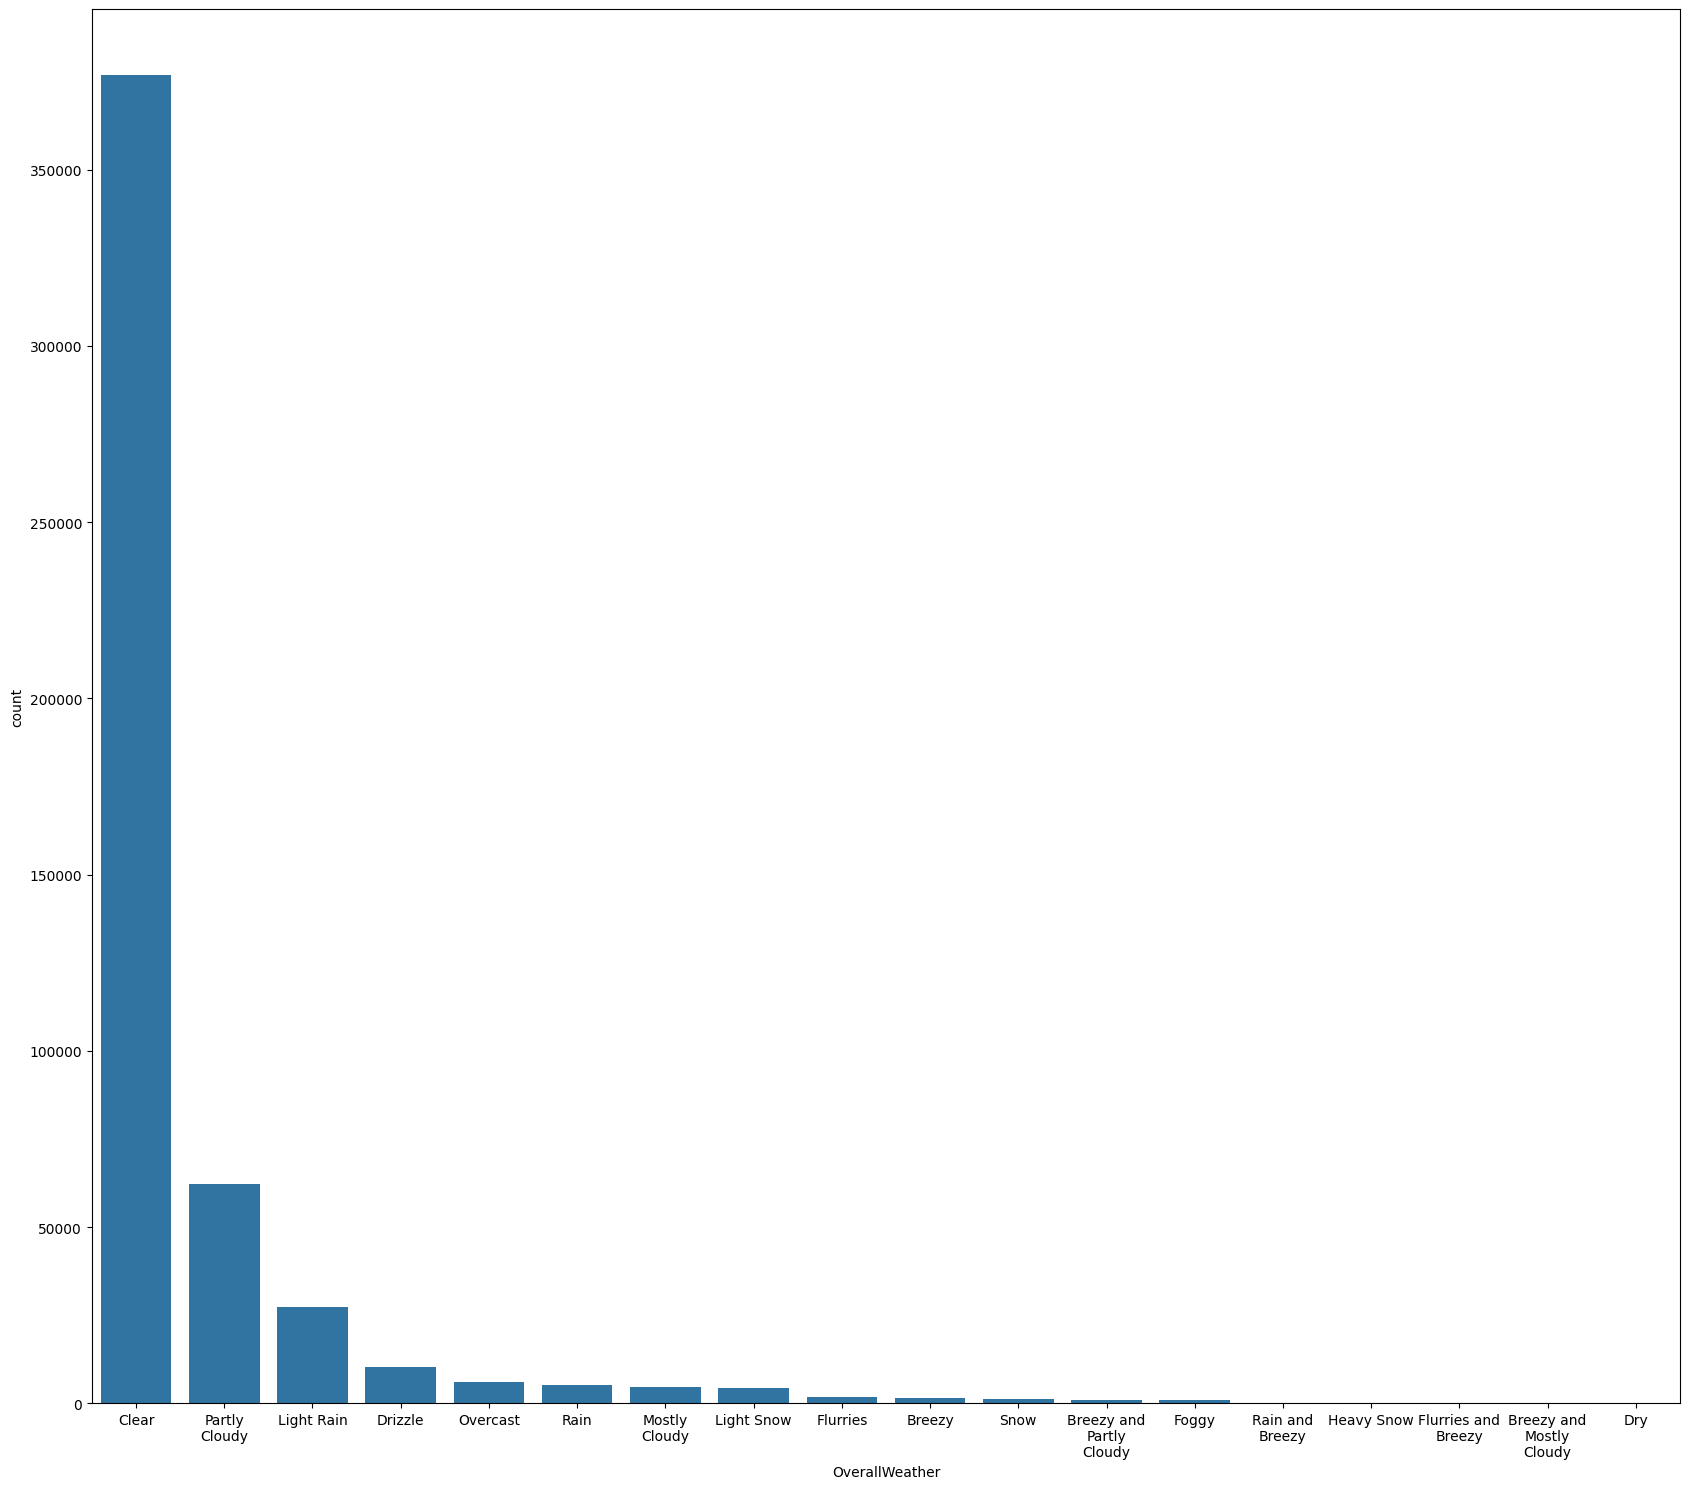

In [64]:
plt.figure(figsize=(17, 15))
order = SmartData["OverallWeather"].value_counts().index
ax = sns.countplot(data=SmartData, x="OverallWeather", order=order)
labels = [textwrap.fill(label.get_text(), width=12) for label in ax.get_xticklabels()]
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
plt.tight_layout()
plt.show()

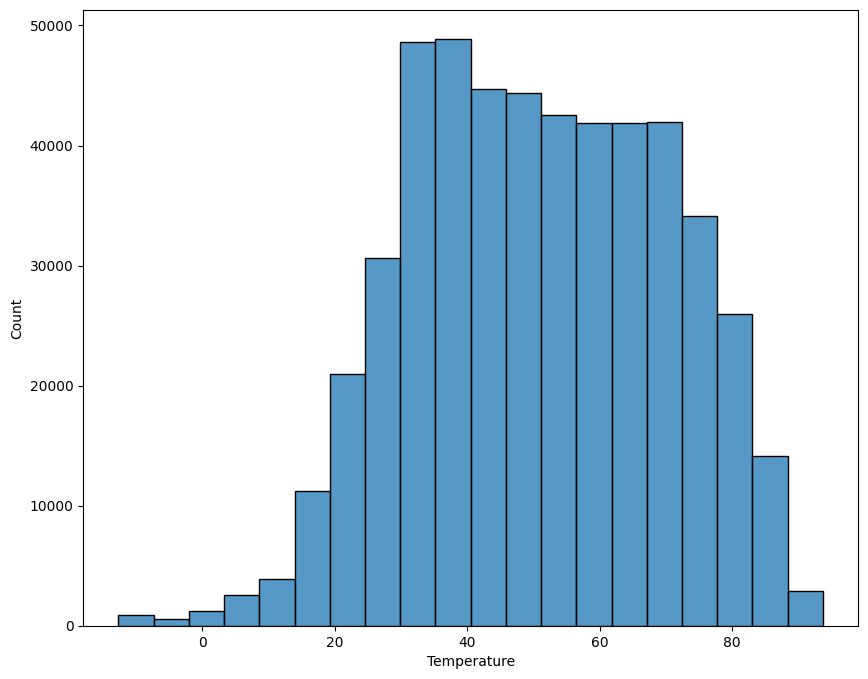

In [65]:
plt.figure(figsize=(10, 8))
sns.histplot(data=SmartData, x="Temperature", bins=20)
plt.show()

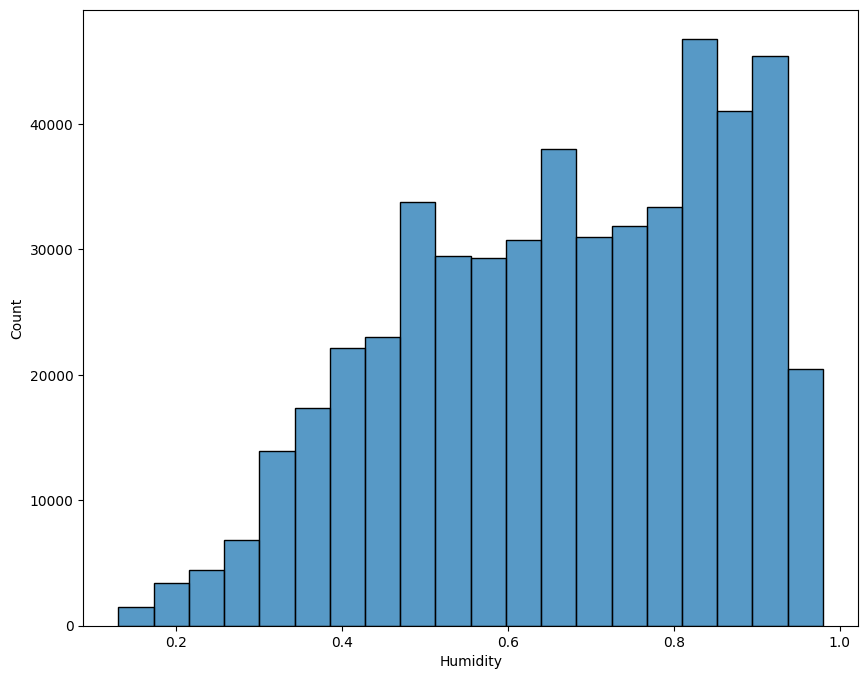

In [67]:
plt.figure(figsize=(10, 8))
sns.histplot(data=SmartData, x="Humidity", bins=20)
plt.show()

*Multi Variable Visualisation*

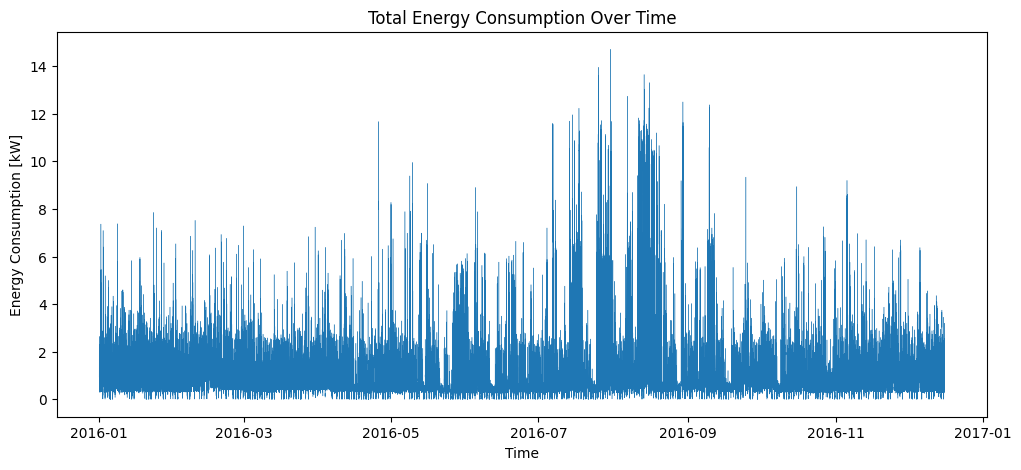

In [77]:
plt.figure(figsize=(12, 5))
plt.plot(SmartData.index, SmartData["EnergyConsumption [kW]"], linewidth=0.3)
plt.title("Total Energy Consumption Over Time")
plt.xlabel("Time")
plt.ylabel("Energy Consumption [kW]")
plt.show()

The diagram is very spikey as appliances turn on and off every minute.

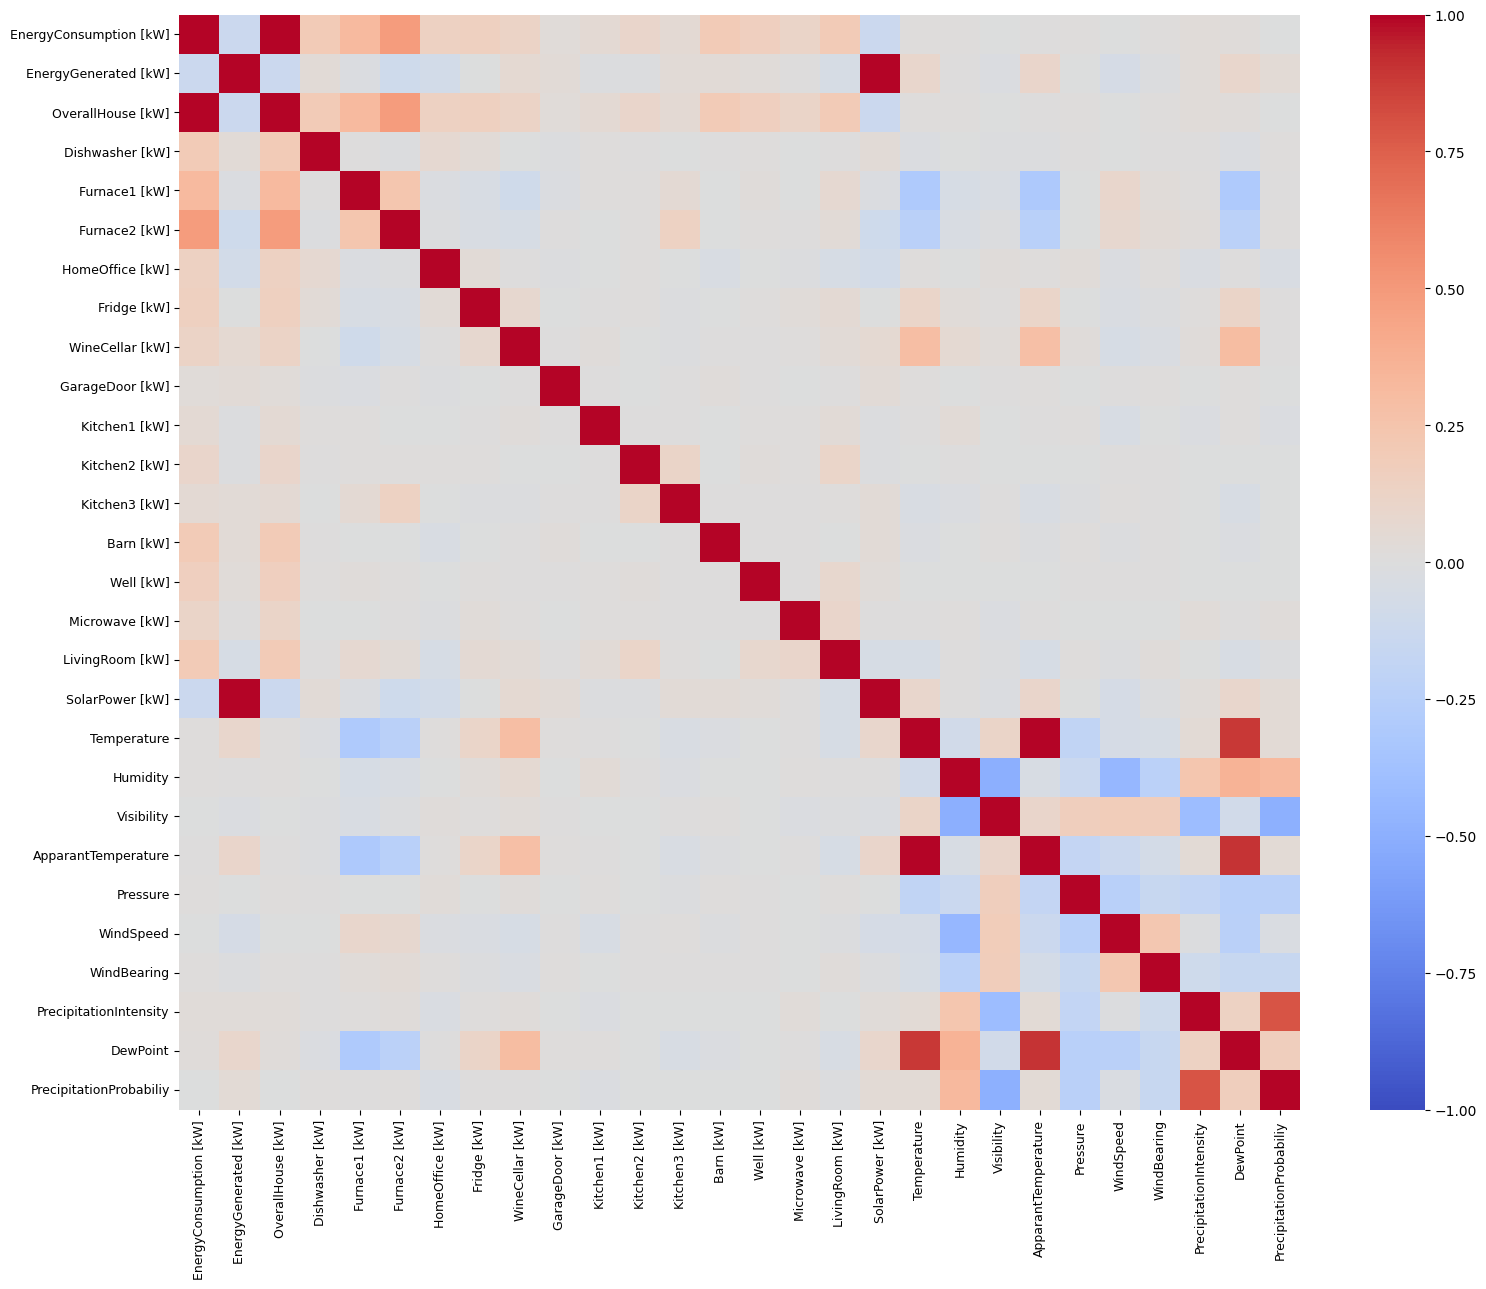

In [98]:
corr = SmartData.select_dtypes("number").corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, xticklabels=True, yticklabels=True)
plt.xticks(rotation=90, fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

*Time Series Visualisation*

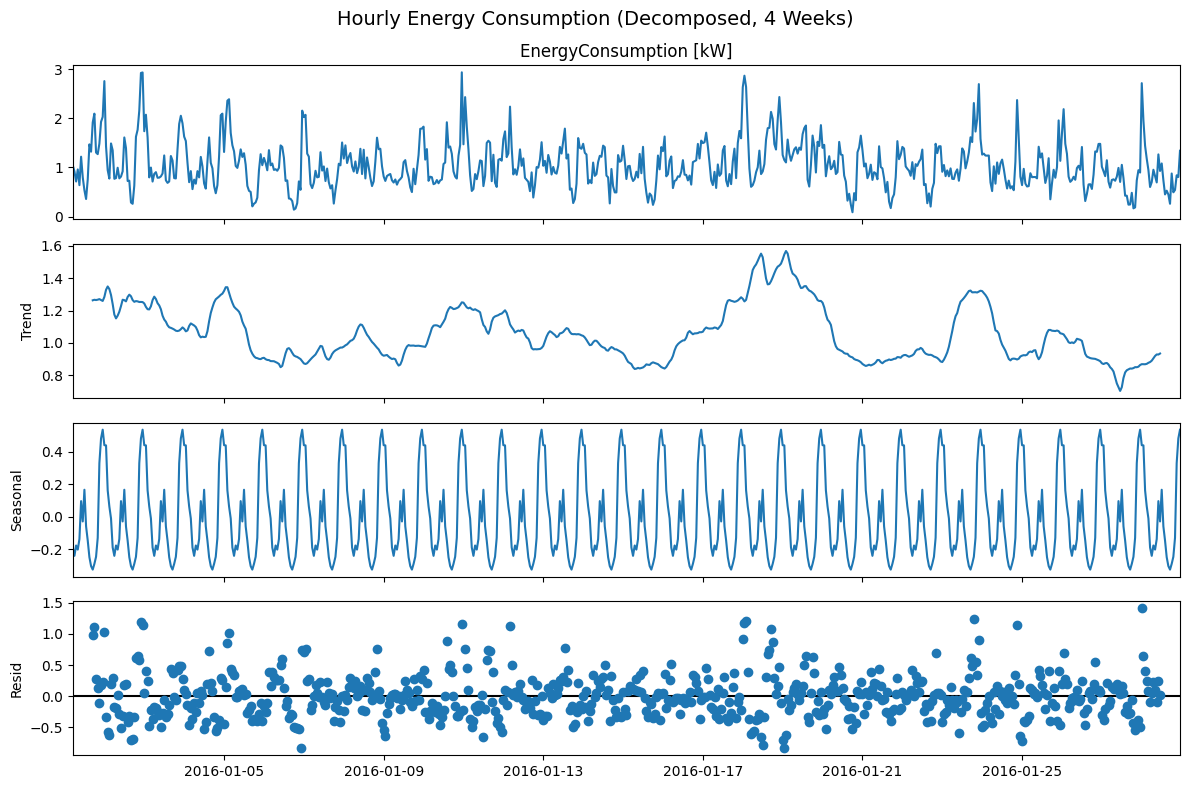

In [88]:
# Decomposition

Sample = yHourly["2016-01-01" : "2016-01-28"]

Decomposition = seasonal_decompose(Sample, model="additive", period=24)
fig = Decomposition.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Hourly Energy Consumption (Decomposed, 4 Weeks)", fontsize=14)
plt.tight_layout()
plt.show()

Data Starts at:  2016-01-01 05:00:00 



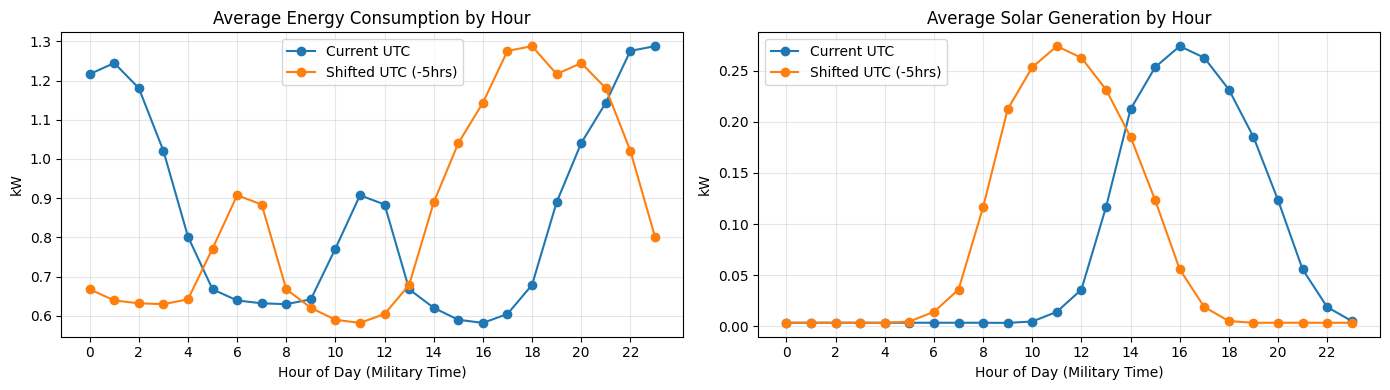


 Solar Power: 

	 UTC: Producing from  12  to  21 . 
 	 Peaks at:  16
	 Shifted UTC: Producing from  7  to  16 . 
 	 Peaks at:  11

 Energy Consumption: 

	 UTC Peak:  23  Shifted Peak:  18


In [86]:
print("Data Starts at: ", SmartData.index[0], "\n")

EnergyConsumption_h = SmartData["EnergyConsumption [kW]"].resample('h').mean()
SolarPower_h = SmartData["SolarPower [kW]"].resample('h').mean()

EnergyConsumption_UTC = EnergyConsumption_h.groupby(EnergyConsumption_h.index.hour).mean()
EnergyConsumption_Local = EnergyConsumption_h.groupby((EnergyConsumption_h.index - pd.Timedelta(hours=5)).hour).mean()
SolarPower_UTC = SolarPower_h.groupby(SolarPower_h.index.hour).mean()
SolarPower_Local = SolarPower_h.groupby((SolarPower_h.index - pd.Timedelta(hours=5)).hour).mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(EnergyConsumption_UTC, marker='o', label="Current UTC")
ax[0].plot(EnergyConsumption_Local, marker='o', label="Shifted UTC (-5hrs)")
ax[0].set_title("Average Energy Consumption by Hour")
ax[0].set_ylabel("kW")

ax[1].plot(SolarPower_UTC, marker='o', label="Current UTC")
ax[1].plot(SolarPower_Local, marker='o', label="Shifted UTC (-5hrs)")
ax[1].set_title("Average Solar Generation by Hour")
ax[1].set_ylabel("kW")

for a in ax:
  a.set_xlabel("Hour of Day (Military Time)")
  a.set_xticks(range(0, 24, 2))
  a.grid(True, alpha=0.3)
  a.legend()

plt.tight_layout()
plt.show()

onUTC = SolarPower_UTC[SolarPower_UTC > SolarPower_UTC.max() * 0.1].index
onLocal = SolarPower_Local[SolarPower_Local > SolarPower_Local.max() * 0.1].index

print("\n Solar Power: \n")
print("\t UTC: Producing from ", onUTC.min(), " to ", onUTC.max(), ". \n \t Peaks at: ", SolarPower_UTC.idxmax())
print("\t Shifted UTC: Producing from ", onLocal.min(), " to ", onLocal.max(), ". \n \t Peaks at: ", SolarPower_Local.idxmax())

print("\n Energy Consumption: \n")
print("\t UTC Peak: ", EnergyConsumption_UTC.idxmax(), " Shifted Peak: ", EnergyConsumption_Local.idxmax())

In [87]:
# A checking loop

if SmartData.index[0].hour == 5:
  SmartData.index = SmartData.index - pd.Timedelta(hours=5)
  print("Shifted. New start: ", SmartData.index[0])

else:
  print("Already shifted. Start: ", SmartData.index[0])

# Unix time is UTC. So we moved every timestamp
# 5 hours back to show the house's local time (UTC-5)

Shifted. New start:  2016-01-01 00:00:00


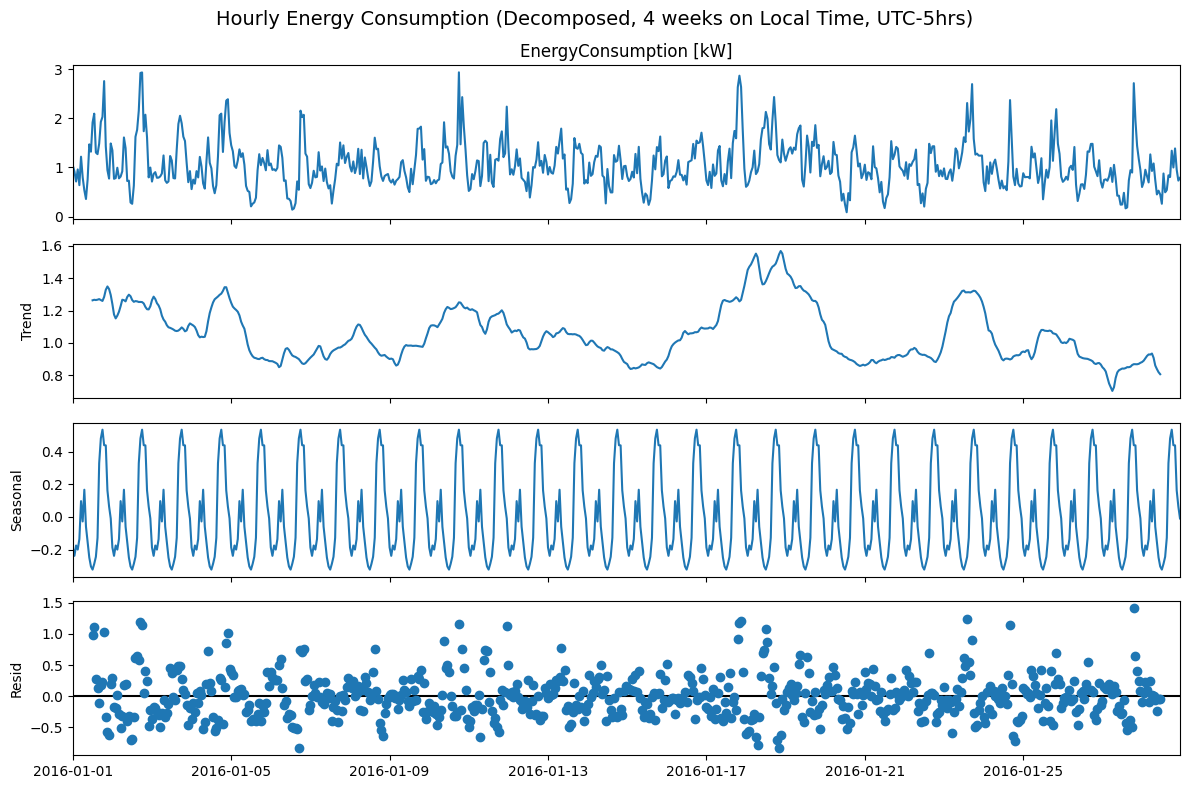

In [90]:
# Checking the decomposition again after shifting the time.

yHourlyLocal = SmartData["EnergyConsumption [kW]"].resample('h').mean()
SampleLocal = yHourlyLocal["2016-01-01" : "2016-01-28"]

LocalDecomposition = seasonal_decompose(SampleLocal, model="additive", period=24)
fig = LocalDecomposition.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Hourly Energy Consumption (Decomposed, 4 weeks on Local Time, UTC-5hrs)", fontsize=14)
plt.tight_layout()
plt.show()

*Relationships Visualisation*

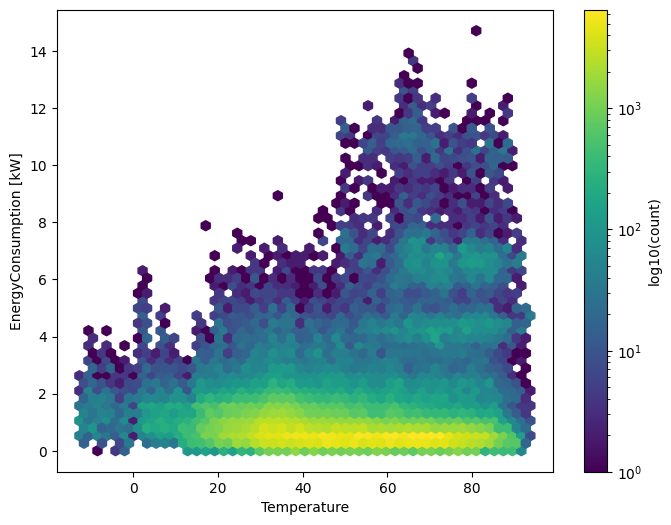

In [106]:
plt.figure(figsize=(8, 6))
Hexbin = plt.hexbin(
    SmartData["Temperature"],
    SmartData["EnergyConsumption [kW]"],
    gridsize=50,
    bins="log",
    cmap="viridis",
    mincnt=1,
)
plt.colorbar(Hexbin, label="log10(count)")
plt.xlabel("Temperature")
plt.ylabel("EnergyConsumption [kW]")
plt.show()

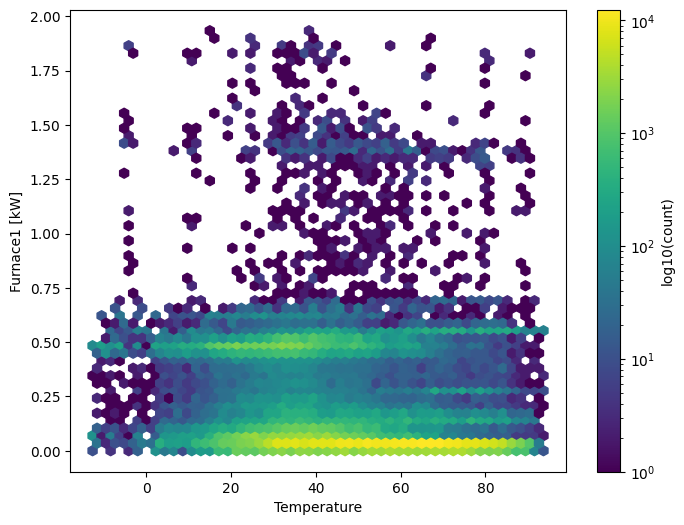

In [107]:
plt.figure(figsize=(8, 6))
Hexbin = plt.hexbin(
    SmartData["Temperature"],
    SmartData["Furnace1 [kW]"],
    gridsize=50,
    bins="log",
    cmap="viridis",
    mincnt=1,
)
plt.colorbar(Hexbin, label="log10(count)")
plt.xlabel("Temperature")
plt.ylabel("Furnace1 [kW]")
plt.show()

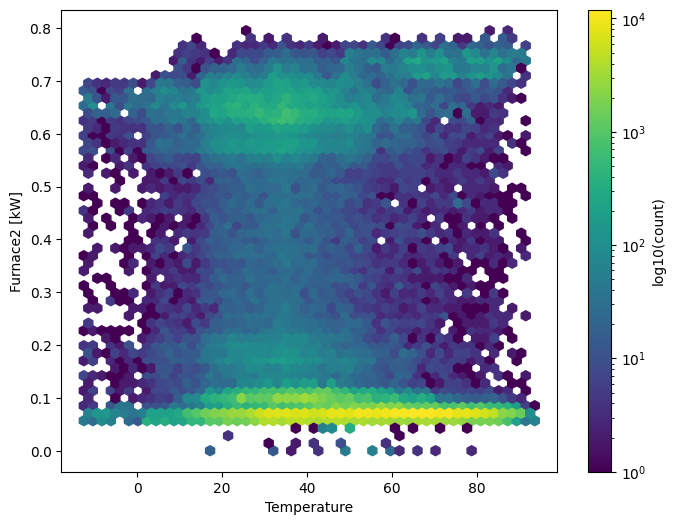

In [108]:
plt.figure(figsize=(8, 6))
Hexbin = plt.hexbin(
    SmartData["Temperature"],
    SmartData["Furnace2 [kW]"],
    gridsize=50,
    bins="log",
    cmap="viridis",
    mincnt=1,
)
plt.colorbar(Hexbin, label="log10(count)")
plt.xlabel("Temperature")
plt.ylabel("Furnace2 [kW]")
plt.show()

---

### Data Handling